In [1]:
%load_ext autoreload
%autoreload 2

import torch
import json
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from einops import rearrange

import finsler_learning.shepplogan_pipeline as sp
from finsler_learning.shepplogan_pipeline.shepplogan_utils import *
from finsler_learning.shepplogan_pipeline import *
from finsler_learning.utils import *

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11")
with open(base_path / "shepplogan_pipeline_config.json", "r") as f:
    config = json.load(f)

config = SheppLoganPipelineConfig(**config)
config.export_path = Path(config.export_path)
config.device = torch.device(config.device)

In [3]:
config

SheppLoganPipelineConfig(n_epochs_regressor=500, b_size_regressor=128, lr_regressor=5e-05, wd_regressor=1e-05, n_epochs_vae=1000, b_size_vae=128, lr_vae=5e-05, wd_vae=0.0, beta=1.0, lbda=1.0, lpip_weight=0.0, n_neighbors=16, margin=0, n_epochs_randers=50, b_size_randers=128, use_dummy_accuracy=False, lr_randers=0.01, wd_randers=1e-06, omega_strength=0.9, b_size_evaluation=32, eta=0.999, alpha=5.0, ema_moment=0.9, n_pts=25, skip_regressor=True, skip_vae=True, skip_randers=True, eval_interpolation=False, eval_extrapolation=True, export_path=PosixPath('/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11'), latent_dim=64, label_noise=0.0, K_cometric=None, IMG_SIZE=256, device=device(type='cuda'), eval_quality_interpolation=False, eval_quality_extrapolation=True, eval_regressor=False, no_symmetric=False, no_randers=False)

In [4]:
model = get_models(latent_dim=config.latent_dim)
dtype = next(model.parameters()).dtype
try_load_pretrained_models(config.export_path, model)
model = model.to(config.device)
model.eval()

spherical_model = get_spherical_model(latent_dim=config.latent_dim)
dtype = next(spherical_model.parameters()).dtype
try_load_pretrained_models(config.export_path / "spherical_vae", spherical_model)
spherical_model = spherical_model.to(config.device)
spherical_model.eval()
0

0

In [5]:
def load_samples_geodesics(
    method_key: str,
    randers: bool,
    config: SheppLoganPipelineConfig,
    model: torch.nn.Module,
    subset_idx: torch.Tensor = None,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads the precomputed geodesic trajectories and their corresponding Kendall tau values for a given method and Randers setting.

    Parameters:
    method_key : str
        The key representing the method used for geodesic computation.
    randers : bool
        Whether the Randers metric was used in the computation.

    Returns:
    x_hat : Tensor (B, T, C, H, W)
        The decoded images along the geodesic trajectories.
    t_traj : Tensor (B, T)
        The time points along the geodesic trajectories.
    kendall_tau : Tensor (B,)
        The Kendall tau values for each trajectory.
    """
    folder_name = f"geodesic_evaluation_{method_key}" + f"{'_randers' if randers else ''}"
    z_traj = torch.load(
        config.export_path / folder_name / "latent_geodesics_test.pth", map_location="cpu"
    )
    t_traj = torch.load(
        config.export_path / folder_name / "geo_t_pred_test.pth", map_location="cpu"
    )
    kendall_tau = torch.load(
        config.export_path / folder_name / "geo_kendall_tau_list_test.pth", map_location="cpu"
    )[0]

    if subset_idx is not None:
        z_traj = z_traj[subset_idx]
        t_traj = t_traj[subset_idx]
        kendall_tau = kendall_tau[subset_idx]

    x_hat = decode_traj(z_traj, model.decoder, config.device).cpu()
    return x_hat, t_traj, kendall_tau


def load_samples_extrapolation(
    method_key: str,
    randers: bool,
    config: SheppLoganPipelineConfig,
    model: torch.nn.Module,
    subset_idx: torch.Tensor = None,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads the precomputed geodesic trajectories and their corresponding Kendall tau values for a given method and Randers setting.

    Parameters:
    method_key : str
        The key representing the method used for geodesic computation.
    randers : bool
        Whether the Randers metric was used in the computation.

    Returns:
    x_hat : Tensor (B, T, C, H, W)
        The decoded images along the geodesic trajectories.
    t_traj : Tensor (B, T)
        The time points along the geodesic trajectories.
    kendall_tau : Tensor (B,)
        The Kendall tau values for each trajectory.
    """
    folder_name = f"extrapolation_evaluation_{method_key}" + f"{'_randers' if randers else ''}"
    z_traj = torch.load(
        config.export_path / folder_name / "extrapolated_traj_test.pth", map_location="cpu"
    )
    t_traj = torch.load(
        config.export_path / folder_name / "extrapolated_time_test.pth", map_location="cpu"
    )
    kendall_tau = torch.load(
        config.export_path / folder_name / "extrapolation_kendall_tau_test.pth",
        map_location="cpu",
    )

    if subset_idx is not None:
        z_traj = z_traj[subset_idx]
        t_traj = t_traj[subset_idx]
        kendall_tau = kendall_tau[subset_idx]

    x_hat = decode_traj(z_traj, model.decoder, config.device).cpu()
    return x_hat, t_traj, kendall_tau

In [6]:
methods = [
    ("Euclidean", "euclidean"),
    ("LAND", "land"),
    ("LAND RBF", "land_rbf"),
    ("CovCentroids", "cov_centroids"),
    ("PBCentroids", "pullback_centroids"),
    # ("RBF PB", "rbf_pullback"),
    # ("PBIG", "pbig"),
    # ("WarpedPB", "warped_pullback"),
    ("Wasserstein", "wasserstein"),
    ("HyperSpherical", "spherical"),
]

In [7]:
# subset_idx = torch.linspace(0, 90-1, 10).long()
subset_idx = torch.randperm(90)[:10].long()

all_res_geodesics = {}
for method_name, method_key in methods:
    # for method_name, method_key in methods[:1]:
    randers = False
    try:
        if method_key == "spherical":
            x_hat, t_traj, kendall_tau = load_samples_geodesics(
                method_key,
                randers,
                config=config,
                model=spherical_model,
                subset_idx=subset_idx,
            )
        else:
            x_hat, t_traj, kendall_tau = load_samples_geodesics(
                method_key, randers, config=config, model=model, subset_idx=subset_idx
            )
        print(f"Loaded {method_name} samples.")
    except FileNotFoundError as e:
        print(f"Skipping {method_name}: files not found.")
        print(e)
        continue
    all_res_geodesics[f"{method_name}"] = {
        "x_hat": x_hat,
        "t_traj": t_traj,
        "kendall_tau": kendall_tau,
    }
    randers = True
    try:
        if method_key == "spherical":
            x_hat, t_traj, kendall_tau = load_samples_geodesics(
                method_key,
                randers,
                config=config,
                model=spherical_model,
                subset_idx=subset_idx,
            )
        else:
            x_hat, t_traj, kendall_tau = load_samples_geodesics(
                method_key, randers, config=config, model=model, subset_idx=subset_idx
            )
        print(f"Loaded {method_name} Randers samples.")
    except FileNotFoundError:
        print(f"Skipping {method_name} Randers: files not found.")
        continue
    all_res_geodesics[f"{method_name} (Randers)"] = {
        "x_hat": x_hat,
        "t_traj": t_traj,
        "kendall_tau": kendall_tau,
    }

Loaded Euclidean samples.
Loaded Euclidean Randers samples.
Loaded LAND samples.
Loaded LAND Randers samples.
Loaded LAND RBF samples.
Loaded LAND RBF Randers samples.
Loaded CovCentroids samples.
Loaded CovCentroids Randers samples.
Loaded PBCentroids samples.
Loaded PBCentroids Randers samples.
Skipping Wasserstein: files not found.
[Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11/geodesic_evaluation_wasserstein/latent_geodesics_test.pth'
Loaded HyperSpherical samples.
Skipping HyperSpherical Randers: files not found.


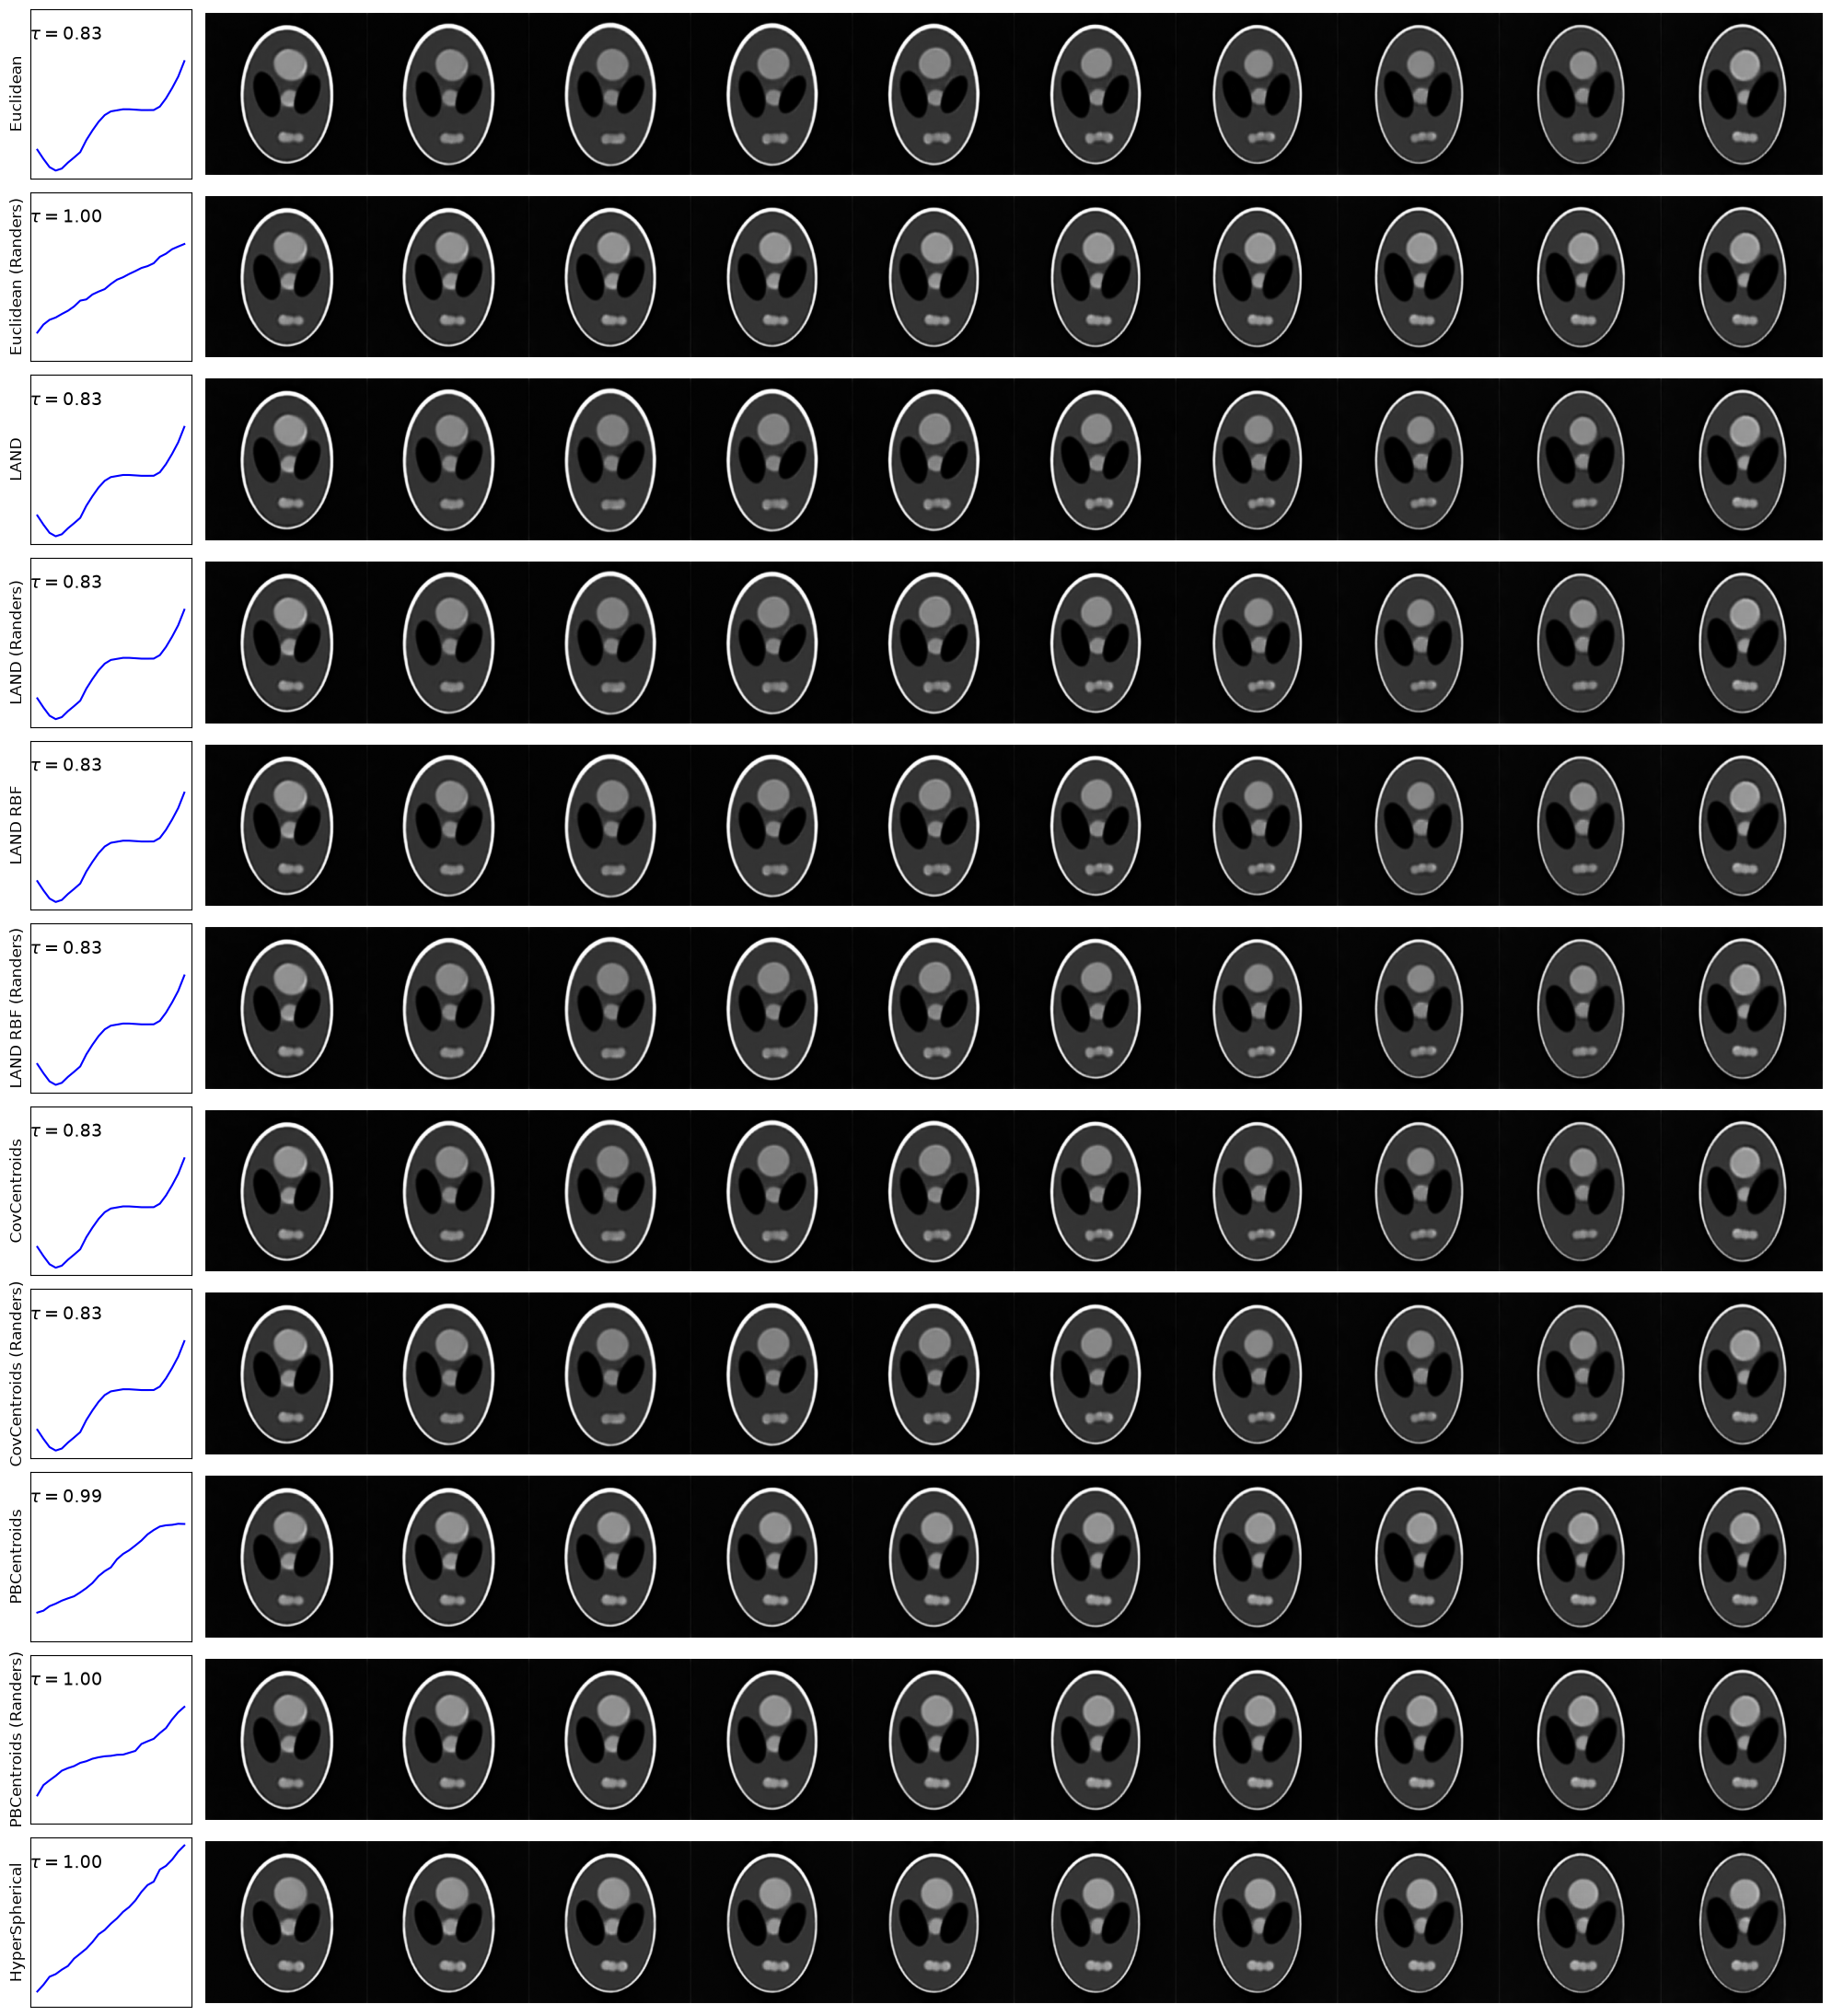

In [8]:
fig, axes = plot_results(all_res_geodesics, idx=0, sharey=True)
plt.savefig(f"./geodesic_results_shepplogan.png", dpi=300, bbox_inches='tight')
# for idx in range(8):
#     fig,axes = plot_results(all_res_geodesics, idx=idx, sharey=True)
#     fig.suptitle(f"{idx = }")
#     plt.show()

In [9]:
# subset_idx = torch.linspace(0, 90-1, 10).long()
subset_idx = torch.randperm(90)[:10].long()

all_res_extrapolation = {}
for method_name, method_key in methods:
    # for method_name, method_key in methods[:1]:
    randers = False
    try:
        if method_key == "spherical":
            x_hat, t_traj, kendall_tau = load_samples_extrapolation(
                method_key,
                randers,
                config=config,
                model=spherical_model,
                subset_idx=subset_idx,
            )
        else:
            x_hat, t_traj, kendall_tau = load_samples_extrapolation(
                method_key, randers, config=config, model=model, subset_idx=subset_idx
            )
        print(f"Loaded {method_name} samples.")
    except FileNotFoundError as e:
        print(f"Skipping {method_name}: files not found.")
        print(e)
        continue
    all_res_extrapolation[f"{method_name}"] = {
        "x_hat": x_hat,
        "t_traj": t_traj,
        "kendall_tau": kendall_tau,
    }
    randers = True
    try:
        if method_key == "spherical":
            x_hat, t_traj, kendall_tau = load_samples_extrapolation(
                method_key,
                randers,
                config=config,
                model=spherical_model,
                subset_idx=subset_idx,
            )
        else:
            x_hat, t_traj, kendall_tau = load_samples_extrapolation(
                method_key, randers, config=config, model=model, subset_idx=subset_idx
            )
        print(f"Loaded {method_name} Randers samples.")
    except FileNotFoundError:
        print(f"Skipping {method_name} Randers: files not found.")
        continue
    all_res_extrapolation[f"{method_name} (Randers)"] = {
        "x_hat": x_hat,
        "t_traj": t_traj,
        "kendall_tau": kendall_tau,
    }

Loaded Euclidean samples.
Loaded Euclidean Randers samples.
Loaded LAND samples.
Loaded LAND Randers samples.
Loaded LAND RBF samples.
Loaded LAND RBF Randers samples.
Loaded CovCentroids samples.
Loaded CovCentroids Randers samples.
Loaded PBCentroids samples.
Loaded PBCentroids Randers samples.
Loaded Wasserstein samples.
Skipping Wasserstein Randers: files not found.
Loaded HyperSpherical samples.
Skipping HyperSpherical Randers: files not found.


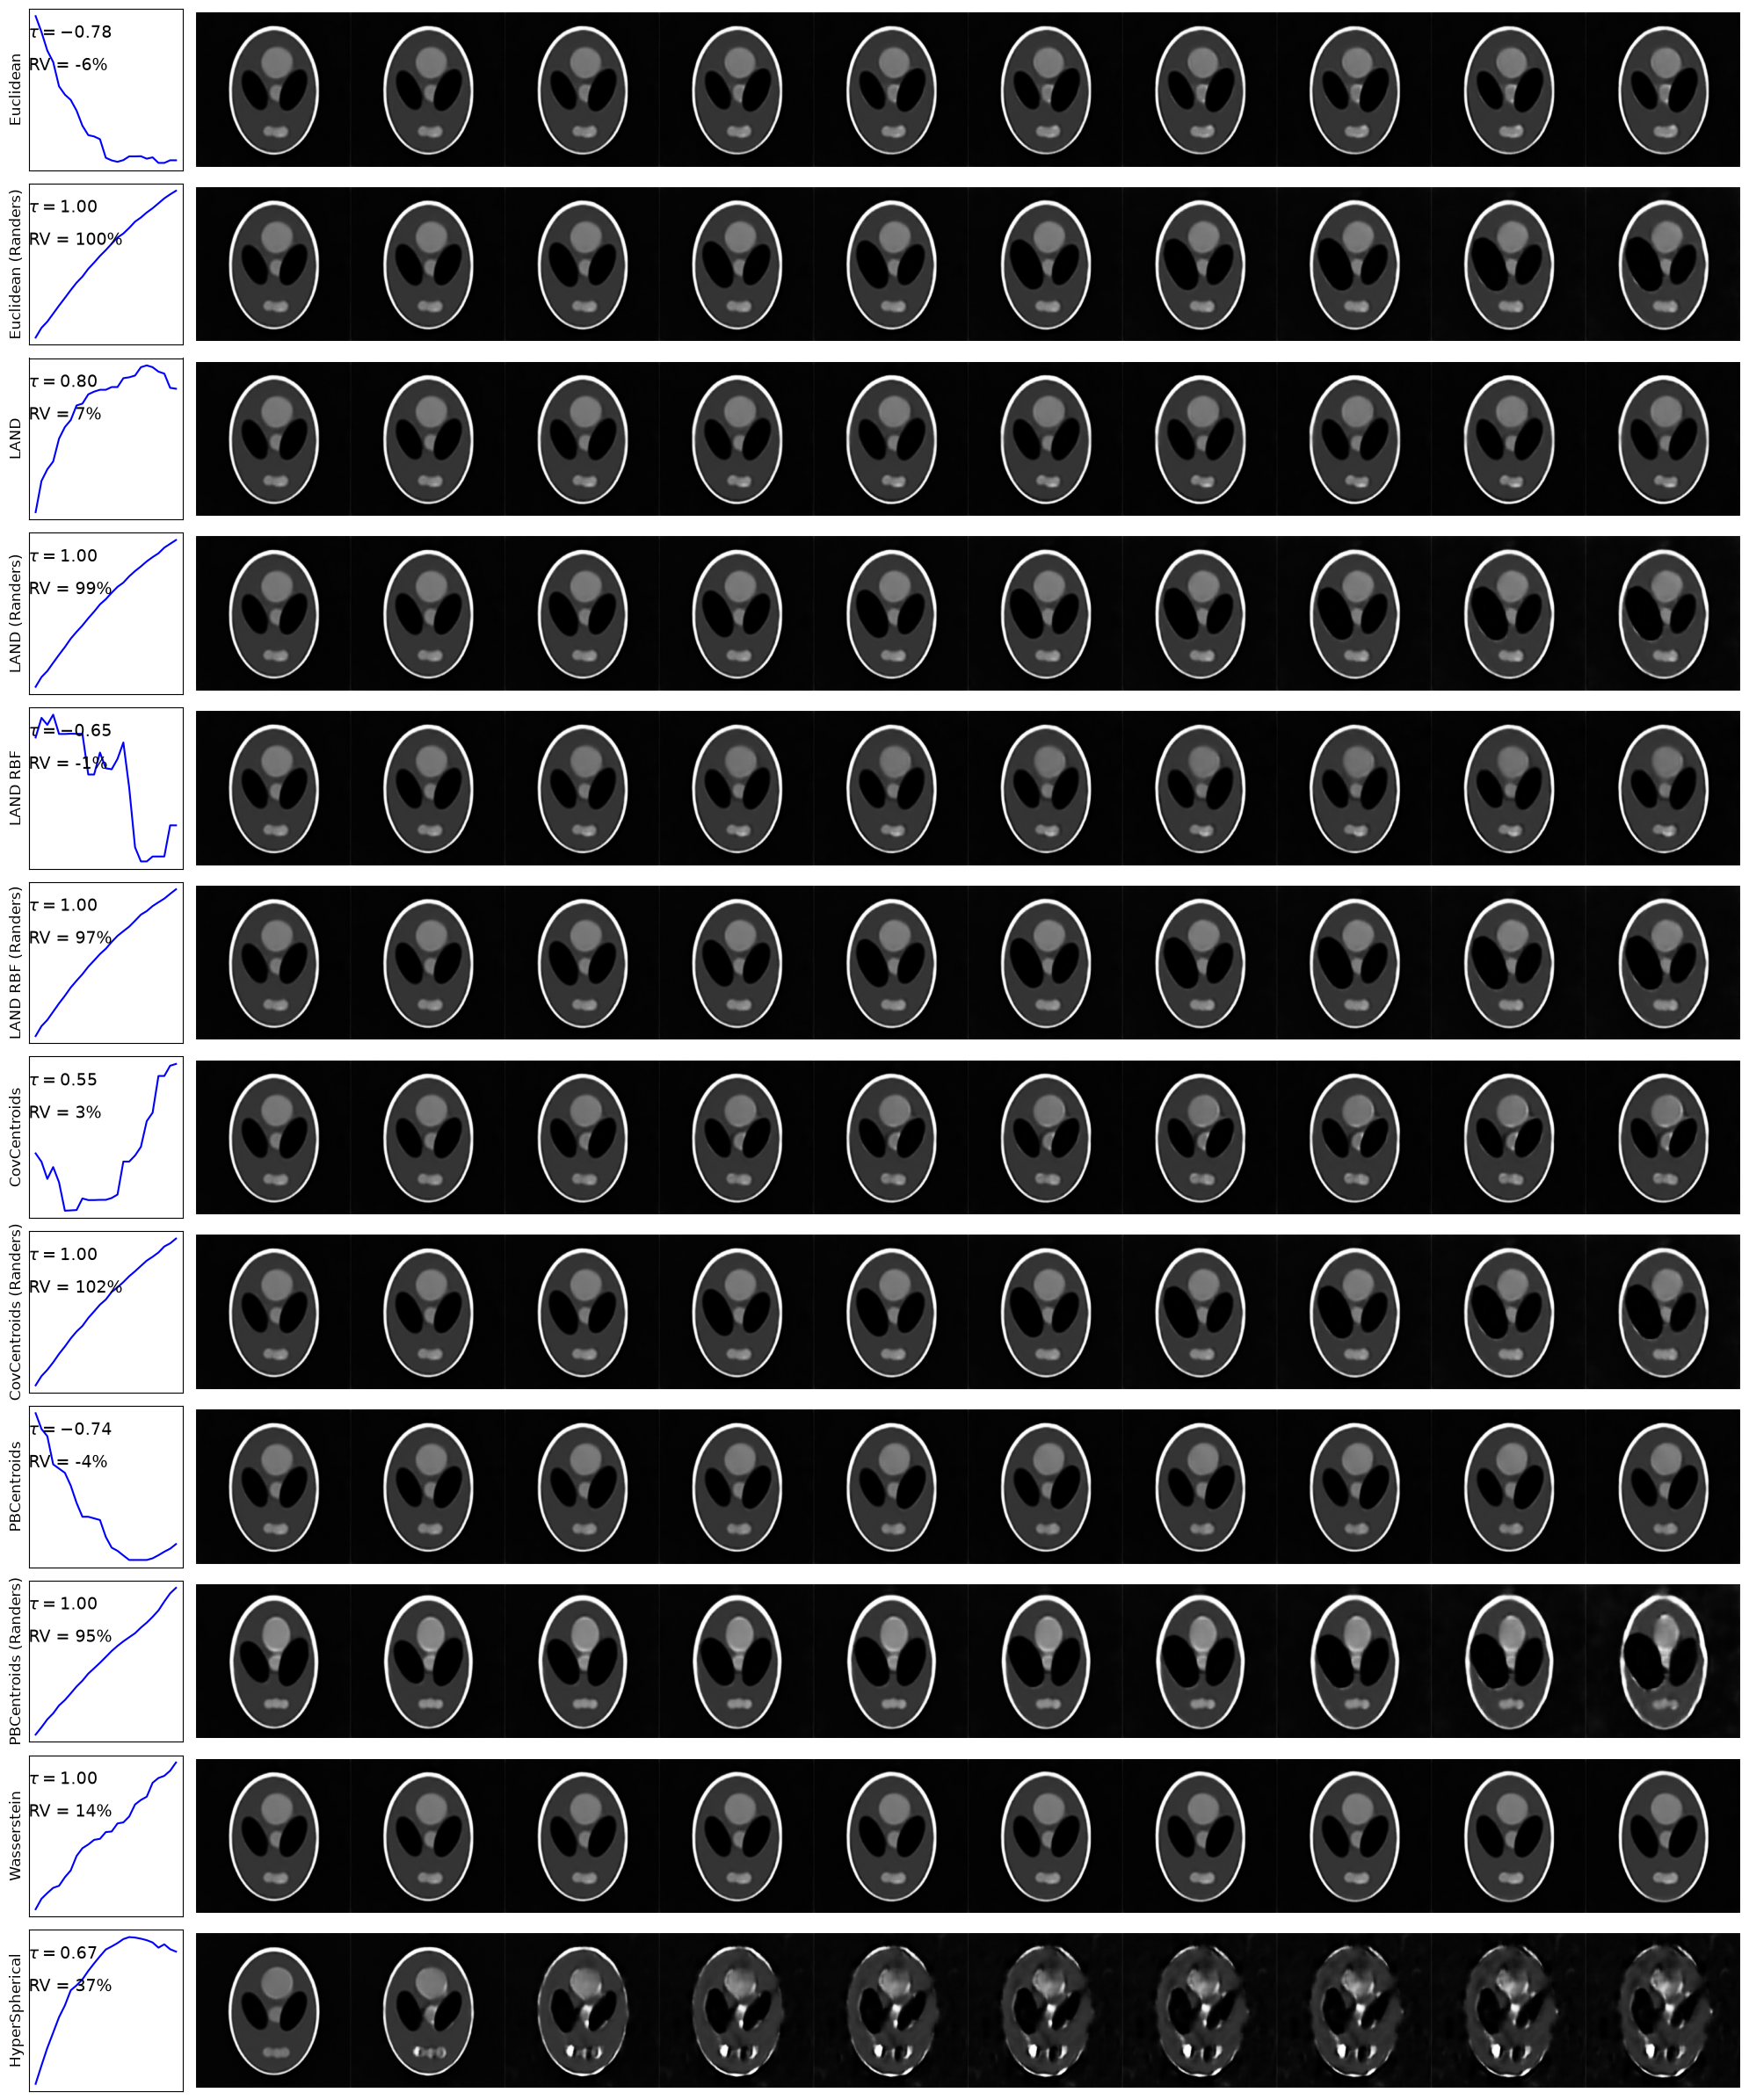

In [10]:
fig, axes = plot_results(
    all_res_extrapolation, idx=3, sharey=False, relative_variation=True, randers_only=False
)
fig.savefig(f"./extrapolation_results_shepplogan.png", dpi=250, bbox_inches='tight')
# for idx in range(3, 6):
#     fig,axes = plot_results(all_res_extrapolation, idx=idx, sharey=False,relative_variation=True,randers_only=False)
#     fig.suptitle(f"{idx = }")

Exporting to /home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11/extrapolation_traj_landrbf_randers.png


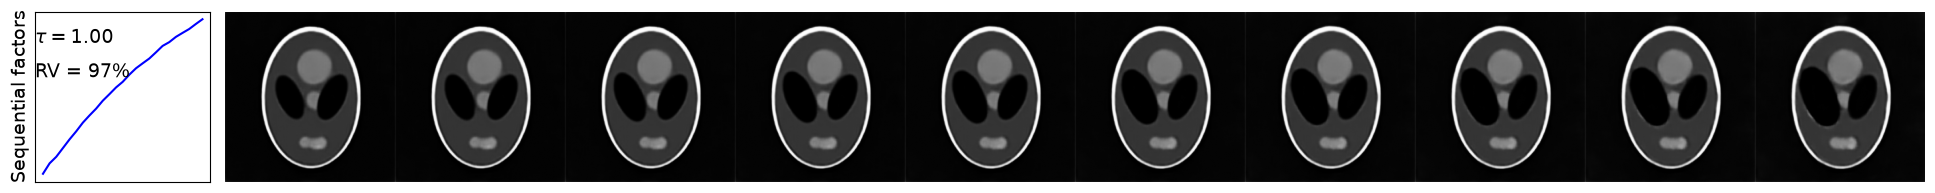

In [11]:
fig, axes = plot_single_traj(
    all_res_extrapolation["LAND RBF (Randers)"], idx=3, relative_variation=True
)
# Save the fig
print(f"Exporting to {config.export_path / 'extrapolation_traj_landrbf_randers.png'}")
plt.savefig(
    config.export_path / "extrapolation_traj_landrbf_randers.png", dpi=300, bbox_inches='tight'
)